# TP5 - Punto 1
## Ley del enfriamiento de Newton

In [2]:
from pathlib import Path
import os

os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd() / ".mplconfig"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.integrate import solve_ivp
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 4.8)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

def resolver_edo_escalar(f, y0, t_final, n=500, rtol=1e-9, atol=1e-12):
    """Resuelve una EDO escalar y devuelve t, y."""
    t_eval = np.linspace(0, t_final, n)
    sol = solve_ivp(
        fun=lambda t, y: [f(t, y[0])],
        t_span=(0, t_final),
        y0=[y0],
        t_eval=t_eval,
        rtol=rtol,
        atol=atol,
    )
    if not sol.success:
        raise RuntimeError(sol.message)
    return sol.t, sol.y[0]

def valores_en(t, y, puntos, nombre="valor"):
    return pd.DataFrame({
        "t": puntos,
        nombre: np.interp(puntos, t, y),
    })

def primer_tiempo_cerca(t, y, objetivo, tolerancia):
    cerca = np.where(np.abs(y - objetivo) <= tolerancia)[0]
    if len(cerca) == 0:
        return np.nan
    return t[cerca[0]]

def mostrar_tabla(df, decimales=4):
    display(df.round(decimales).style.hide(axis="index"))

## 1. Ley del enfriamiento de Newton

Modelo:

`dT/dt = -k (T - Tamb)`

En esta seccion se toma el tiempo `t` en minutos y todas las temperaturas en grados Celsius (`C`). Esto es importante porque mas adelante se usa `-273.15 C` como cero absoluto.

Por eso `k` tiene unidades de `1/min` o `min^-1`, porque el producto `k*t` debe ser adimensional en el exponente.

El valor numerico de `k` depende de la unidad de tiempo elegida. Por ejemplo, `0.5 min^-1` equivale a `30 h^-1`. Entonces comparar `k` con `1` no tiene significado fisico si no se indica la unidad.

La clasificacion importante depende del signo de `k`:

- `k > 0`: la temperatura se acerca a `Tamb`. Es el comportamiento fisico esperado.
- `k = 0`: temperatura constante. Es un caso limite ideal de aislamiento perfecto: `dT/dt = 0` y, como `e^0 = 1`, queda `T(t) = T0`.
- `k < 0`: la temperatura se aleja de `Tamb`. La ecuacion se puede resolver, pero no representa enfriamiento real.

Caso base: T0=90, Tamb=20, k=0.08 min^-1
Error maximo contra la formula cerrada: 2.10e-08


t,T(t)
0,90.000000
10,51.453200
30,26.350300
60,20.576100


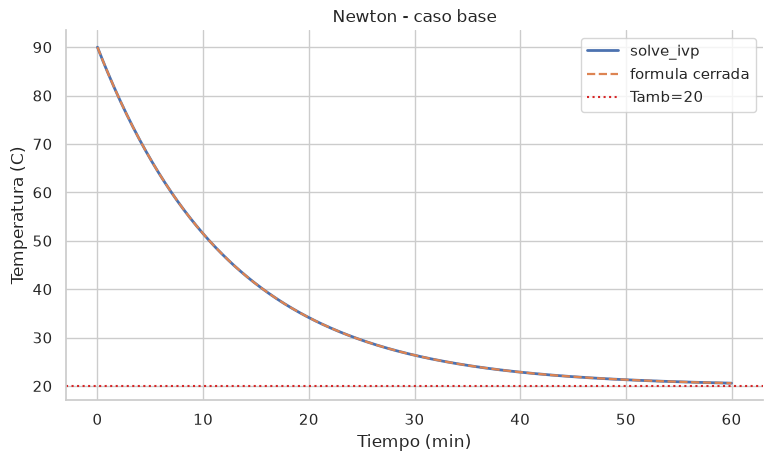

In [3]:
def newton_rhs(Tamb, k):
    return lambda t, T: -k * (T - Tamb)

def resolver_newton(T0=90, Tamb=20, k=0.08, t_final=60):
    return resolver_edo_escalar(newton_rhs(Tamb, k), T0, t_final)

def newton_teorica(t, T0, Tamb, k):
    return Tamb + (T0 - Tamb) * np.exp(-k * t)

T0 = 90
Tamb = 20
k = 0.08
t, T = resolver_newton(T0=T0, Tamb=Tamb, k=k, t_final=60)
T_exacta = newton_teorica(t, T0, Tamb, k)

print(f"Caso base: T0={T0}, Tamb={Tamb}, k={k} min^-1")
print(f"Error maximo contra la formula cerrada: {np.max(np.abs(T - T_exacta)):.2e}")
mostrar_tabla(valores_en(t, T, [0, 10, 30, 60], "T(t)"))

plt.plot(t, T, label="solve_ivp", linewidth=2)
plt.plot(t, T_exacta, "--", label="formula cerrada", linewidth=1.6)
plt.axhline(Tamb, color="tab:red", linestyle=":", label=f"Tamb={Tamb}")
plt.title("Newton - caso base")
plt.xlabel("Tiempo (min)")
plt.ylabel("Temperatura (C)")
plt.legend()
plt.show()

### Variar `k` con `Tamb` fijo

Primero se mantiene `Tamb` fijo y se cambia `k`. Para `k >= 0`, todas las curvas tienen la misma idea: se acercan al ambiente. Lo que cambia es la rapidez.

La constante de tiempo `1/k` indica una escala util: despues de `1/k` minutos, la diferencia `T - Tamb` queda reducida a aproximadamente el `37%` de la diferencia inicial. Para `k <= 0` no se usa esta interpretacion, por eso se deja como `NaN`.

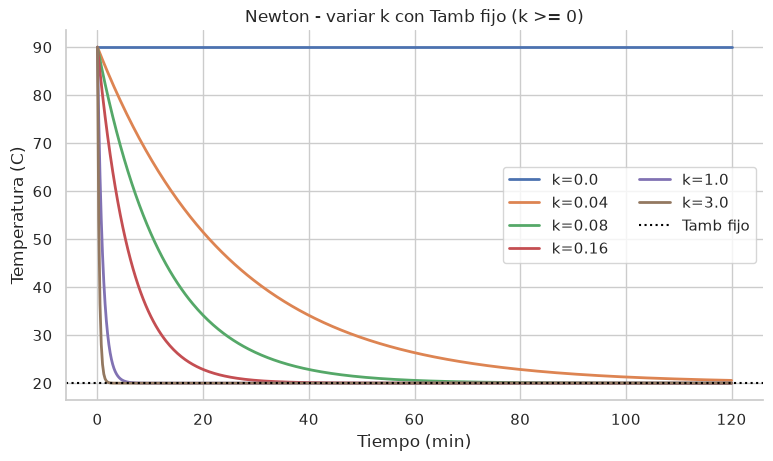

k,constante de tiempo 1/k,T(120),tiempo hasta quedar a 1 grado de Tamb,interpretacion
0.000000,nan,90.000000,nan,temperatura constante
0.040000,25.000000,20.576100,106.292600,se acerca a Tamb mas rapido cuanto mayor es k
0.080000,12.500000,20.004700,53.146300,se acerca a Tamb mas rapido cuanto mayor es k
0.160000,6.250000,20.000000,26.693400,se acerca a Tamb mas rapido cuanto mayor es k
1.000000,1.000000,20.000000,4.328700,se acerca a Tamb mas rapido cuanto mayor es k
3.000000,0.333300,20.000000,1.442900,se acerca a Tamb mas rapido cuanto mayor es k


In [4]:
T0 = 90
Tamb = 20
k_valores_no_negativos = [0.00, 0.04, 0.08, 0.16, 1.00, 3.00]
resumen = []

plt.figure(figsize=(9, 4.8))
for ki in k_valores_no_negativos:
    t, T = resolver_newton(T0=T0, Tamb=Tamb, k=ki, t_final=120)
    plt.plot(t, T, linewidth=2, label=f"k={ki}")
    resumen.append({
        "k": ki,
        "constante de tiempo 1/k": np.nan if ki <= 0 else 1 / ki,
        "T(120)": T[-1],
        "tiempo hasta quedar a 1 grado de Tamb": primer_tiempo_cerca(t, T, Tamb, 1),
        "interpretacion": "temperatura constante" if ki == 0 else "se acerca a Tamb mas rapido cuanto mayor es k",
    })

plt.axhline(Tamb, color="black", linestyle=":", label="Tamb fijo")
plt.title("Newton - variar k con Tamb fijo (k >= 0)")
plt.xlabel("Tiempo (min)")
plt.ylabel("Temperatura (C)")
plt.legend(ncol=2)
plt.show()

mostrar_tabla(pd.DataFrame(resumen))

Para `k < 0` conviene usar otro grafico. Como la diferencia con `Tamb` crece exponencialmente, esas curvas pueden hacerse muy grandes y aplastar visualmente las curvas fisicas con `k >= 0`.

En este caso se usa `T0 = 90` como temperatura inicial del objeto y `Tamb = 20` como temperatura ambiente fija.

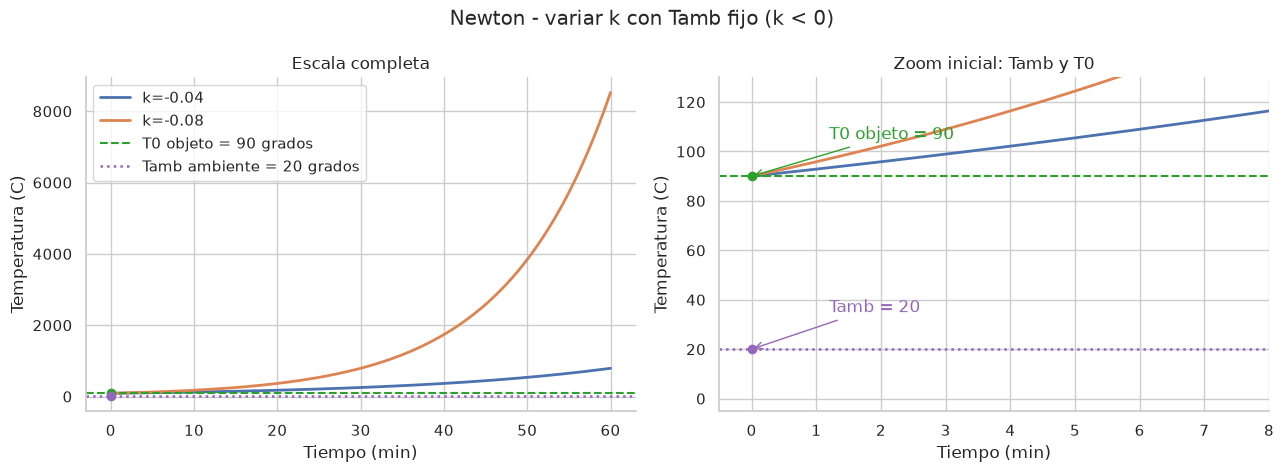

k,constante de tiempo 1/k,T(60),interpretacion
-0.040000,nan,791.622300,"se aleja de Tamb, sin sentido fisico para enfriamiento"
-0.080000,nan,8525.729200,"se aleja de Tamb, sin sentido fisico para enfriamiento"


In [5]:
T0 = 90
Tamb = 20
k_valores_negativos = [-0.04, -0.08]
resumen = []
curvas = []

for ki in k_valores_negativos:
    t, T = resolver_newton(T0=T0, Tamb=Tamb, k=ki, t_final=60)
    curvas.append((ki, t, T))
    resumen.append({
        "k": ki,
        "constante de tiempo 1/k": np.nan,
        "T(60)": T[-1],
        "interpretacion": "se aleja de Tamb, sin sentido fisico para enfriamiento",
    })

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

for ax in axes:
    for ki, t, T in curvas:
        ax.plot(t, T, linewidth=2, label=f"k={ki}")
    ax.axhline(T0, color="tab:green", linestyle="--", linewidth=1.5, label=f"T0 objeto = {T0} grados")
    ax.axhline(Tamb, color="tab:purple", linestyle=":", linewidth=1.8, label=f"Tamb ambiente = {Tamb} grados")
    ax.scatter([0], [T0], color="tab:green", zorder=5)
    ax.scatter([0], [Tamb], color="tab:purple", zorder=5)
    ax.set_xlabel("Tiempo (min)")
    ax.set_ylabel("Temperatura (C)")

axes[0].set_title("Escala completa")
axes[1].set_title("Zoom inicial: Tamb y T0")
axes[1].set_xlim(-0.5, 8)
axes[1].set_ylim(-5, 130)
axes[1].annotate("T0 objeto = 90", xy=(0, T0), xytext=(1.2, 105), arrowprops={"arrowstyle": "->", "color": "tab:green"}, color="tab:green")
axes[1].annotate("Tamb = 20", xy=(0, Tamb), xytext=(1.2, 35), arrowprops={"arrowstyle": "->", "color": "tab:purple"}, color="tab:purple")

fig.suptitle("Newton - variar k con Tamb fijo (k < 0)")
axes[0].legend()
plt.tight_layout()
plt.show()

tabla = pd.DataFrame(resumen).round(4)
display(
    tabla.style.hide(axis="index").set_properties(
        subset=["interpretacion"],
        **{"white-space": "normal", "text-align": "left"}
    )
)

### Caso `k < 0`

Con `k < 0` se invierte el signo de la ecuacion. Si `T > Tamb`, entonces `dT/dt > 0` y el objeto se calienta. Si `T < Tamb`, entonces `dT/dt < 0` y el objeto se enfria. En ambos casos la diferencia con `Tamb` crece exponencialmente sin limite, igual que en un modelo de Malthus.

Esto no tiene sentido fisico para enfriamiento porque contradice que el calor fluye de lo caliente a lo frio, de acuerdo con la segunda ley de la termodinamica.

En el caso frio se agrega la linea de cero absoluto (`-273.15`). Si la curva la cruza, es una prueba clara de que el resultado numerico no representa nada real.

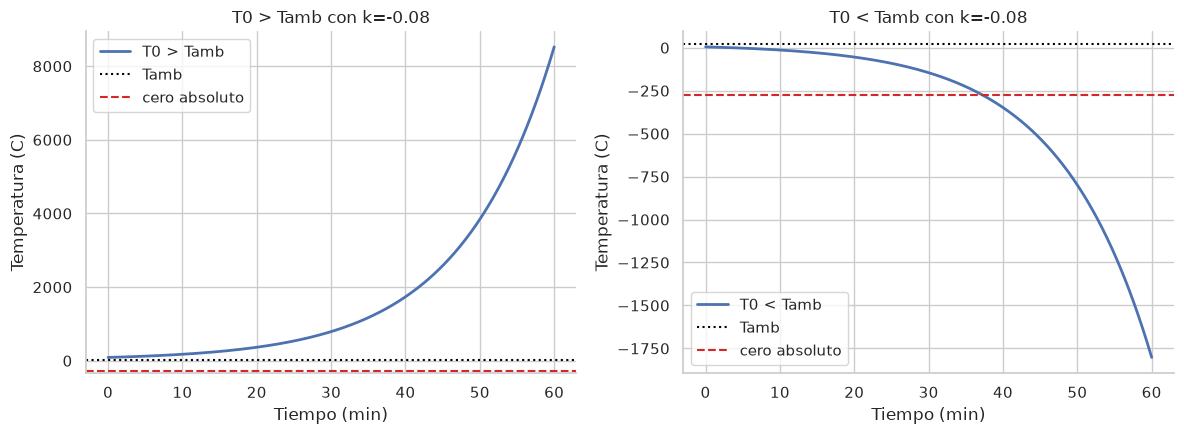

caso,T0,Tamb,k,T(60),cruza cero absoluto,t de cruce,interpretacion
T0 > Tamb,90,20,-0.080000,8525.729200,no,no cruza,se calienta sin limite
T0 < Tamb,5,20,-0.080000,-1802.656300,si,37.274549,se enfria sin limite


In [6]:
Tamb = 20
k = -0.08
cero_absoluto = -273.15
escenarios = [
    {"caso": "T0 > Tamb", "T0": 90, "interpretacion": "se calienta sin limite"},
    {"caso": "T0 < Tamb", "T0": 5, "interpretacion": "se enfria sin limite"},
]
filas = []

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
for ax, escenario in zip(axes, escenarios):
    t, T = resolver_newton(T0=escenario["T0"], Tamb=Tamb, k=k, t_final=60)
    cruces = np.where(T <= cero_absoluto)[0]
    cruza = len(cruces) > 0
    t_cruce = t[cruces[0]] if cruza else "no cruza"

    ax.plot(t, T, linewidth=2, label=escenario["caso"])
    ax.axhline(Tamb, color="black", linestyle=":", label="Tamb")
    ax.axhline(cero_absoluto, color="tab:red", linestyle="--", label="cero absoluto")
    ax.set_title(f"{escenario['caso']} con k={k}")
    ax.set_xlabel("Tiempo (min)")
    ax.set_ylabel("Temperatura (C)")
    ax.legend()

    filas.append({
        "caso": escenario["caso"],
        "T0": escenario["T0"],
        "Tamb": Tamb,
        "k": k,
        "T(60)": T[-1],
        "cruza cero absoluto": "si" if cruza else "no",
        "t de cruce": t_cruce,
        "interpretacion": escenario["interpretacion"],
    })

plt.tight_layout()
plt.show()

mostrar_tabla(pd.DataFrame(filas))

### Variar `Tamb` con `k` fijo

En este caso se deja fija la temperatura inicial del objeto (`T0 = 90`) y tambien la constante de enfriamiento (`k = 0.08 min^-1`). Lo unico que cambia es la temperatura ambiente `Tamb`.

La linea amarilla marca la temperatura inicial del objeto. Cada curva parte desde ese mismo valor, pero termina acercandose a un equilibrio distinto, porque cada valor de `Tamb` define una temperatura ambiente diferente. Las lineas horizontales punteadas marcan esos valores de `Tamb`.

Para que el grafico sea mas claro, se separan los casos en dos paneles: a la izquierda aparecen ambientes mas frios que el objeto (`Tamb < T0`), y a la derecha el equilibrio inicial y un ambiente mas caliente (`Tamb >= T0`). La linea negra marca `T = 0`; por debajo de esa linea aparecen temperaturas negativas.

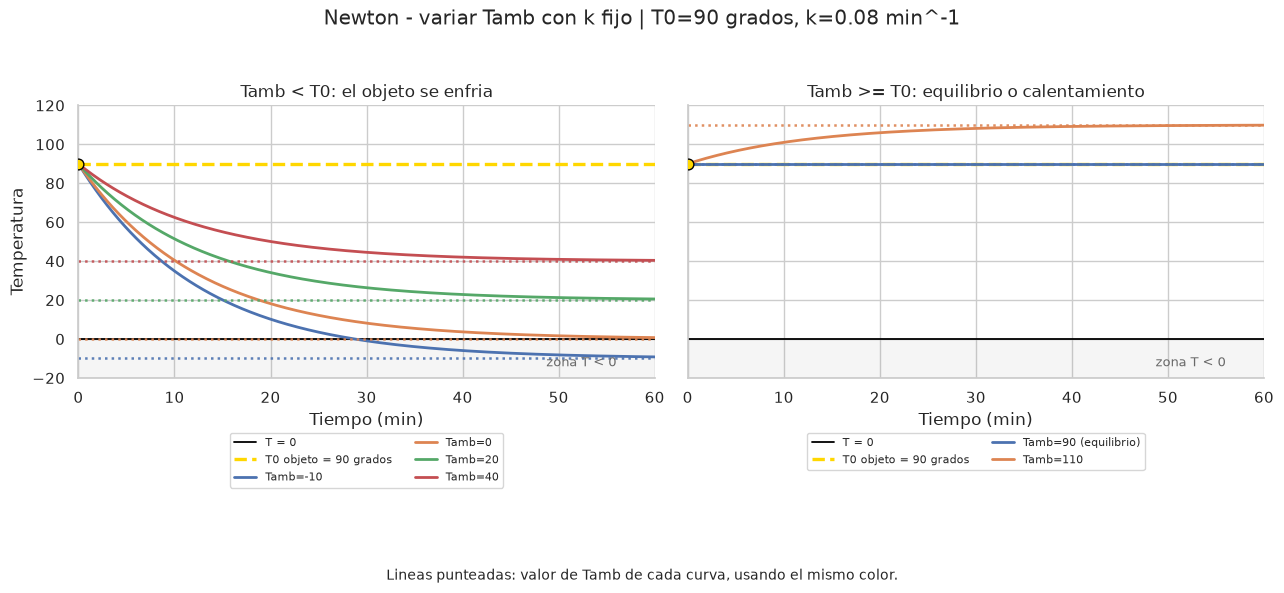

Tamb,T(0),T(60),tipo de movimiento,interpretacion
-10,90.000000,-9.177000,enfriamiento,el objeto pierde calor hacia el ambiente
0,90.000000,0.740700,enfriamiento,el objeto pierde calor hacia el ambiente
20,90.000000,20.576100,enfriamiento,el objeto pierde calor hacia el ambiente
40,90.000000,40.411500,enfriamiento,el objeto pierde calor hacia el ambiente
90,90.000000,90.000000,equilibrio desde el inicio,T0 ya coincide con el equilibrio
110,90.000000,109.835400,calentamiento,el ambiente esta mas caliente que el objeto


In [7]:
T0 = 90
k = 0.08
Tamb_valores = [-10, 0, 20, 40, 90, 110]
resumen = []

fig, axes = plt.subplots(1, 2, figsize=(13, 6.2), sharey=True)
paneles = [
    (axes[0], [Tambi for Tambi in Tamb_valores if Tambi < T0], "Tamb < T0: el objeto se enfria"),
    (axes[1], [Tambi for Tambi in Tamb_valores if Tambi >= T0], "Tamb >= T0: equilibrio o calentamiento"),
]

for ax, valores_panel, titulo_panel in paneles:
    ax.set_ylim(-20, 120)
    ax.axhspan(-20, 0, color="gray", alpha=0.08)
    ax.axhline(0, color="black", linestyle="-", linewidth=1.3, label="T = 0")
    ax.axhline(T0, color="gold", linestyle="--", linewidth=2.4, label=f"T0 objeto = {T0} grados")
    ax.scatter([0], [T0], color="gold", edgecolor="black", s=60, zorder=5)

    for Tambi in valores_panel:
        t, T = resolver_newton(T0=T0, Tamb=Tambi, k=k, t_final=60)
        etiqueta = f"Tamb={Tambi}"
        if Tambi == T0:
            etiqueta += " (equilibrio)"
        linea, = ax.plot(t, T, linewidth=2, label=etiqueta)
        color = linea.get_color()
        ax.axhline(Tambi, color=color, linestyle=":", linewidth=1.8, alpha=0.9)

        resumen.append({
            "Tamb": Tambi,
            "T(0)": T[0],
            "T(60)": T[-1],
            "tipo de movimiento": (
                "equilibrio desde el inicio" if Tambi == T0 else
                "calentamiento" if Tambi > T0 else
                "enfriamiento"
            ),
            "interpretacion": (
                "T0 ya coincide con el equilibrio" if Tambi == T0 else
                "el ambiente esta mas caliente que el objeto" if Tambi > T0 else
                "el objeto pierde calor hacia el ambiente"
            ),
        })

    ax.text(56, -14, "zona T < 0", color="dimgray", ha="right", fontsize=9)
    ax.set_xlim(0, 60)
    ax.set_title(titulo_panel)
    ax.set_xlabel("Tiempo (min)")
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=True)

axes[0].set_ylabel("Temperatura")
fig.suptitle(f"Newton - variar Tamb con k fijo | T0={T0} grados, k={k} min^-1", y=0.98)
fig.text(0.5, 0.06, "Lineas punteadas: valor de Tamb de cada curva, usando el mismo color.", ha="center", fontsize=10)
plt.tight_layout(rect=(0, 0.12, 1, 0.95))
plt.show()

mostrar_tabla(pd.DataFrame(resumen).sort_values("Tamb"))

### Variar `T0` con `k` y `Tamb` fijos

Si `k` y `Tamb` quedan fijos, cambiar `T0` solo cambia la diferencia inicial entre el objeto y el ambiente. El tiempo para que esa diferencia se reduzca a la mitad es siempre `ln(2)/k`, igual que la vida media del decaimiento radioactivo del punto 3.

En esta tabla `Tamb = 20 C` y `k = 0.08 min^-1`. Por eso el tiempo mitad es el mismo para todos los `T0`: aproximadamente `8.66 min`. Lo que cambia es el valor absoluto de la diferencia.

Se agrega tambien un `T0` negativo como caso raro. Puede interpretarse como un objeto bajo cero que se coloca en un ambiente de `20 C`. En ese caso el objeto se calienta hacia `Tamb`, pero la diferencia con el ambiente tambien se reduce a la mitad en `8.66 min`.

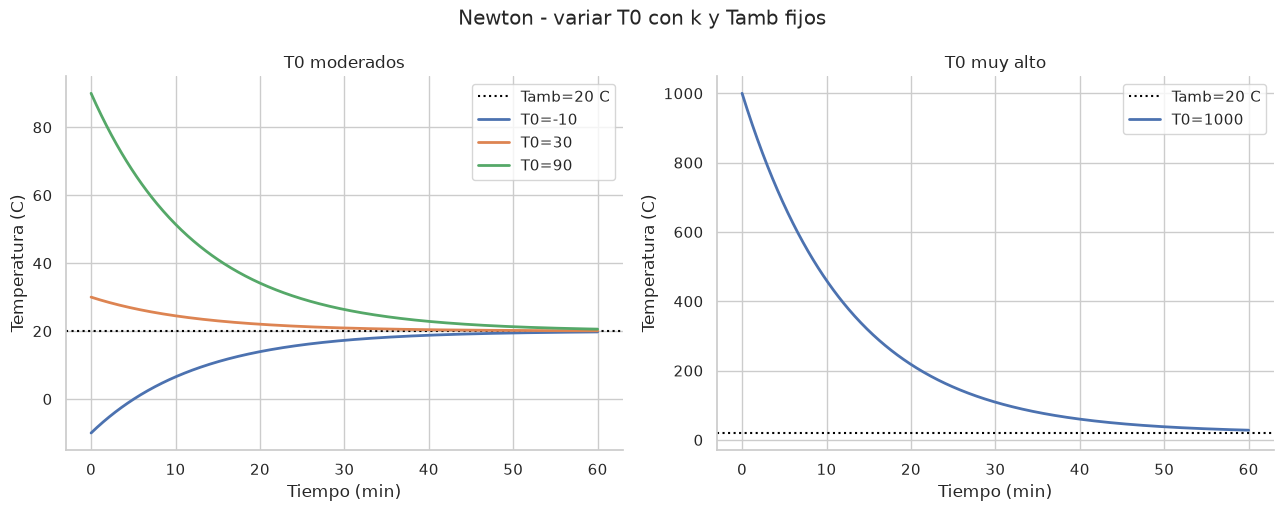

T0 del objeto,Tamb fijo,diferencia inicial,tiempo mitad ln(2)/k,T en tiempo mitad,diferencia restante,interpretacion
-10,20,30,8.664300,5.000000,15.000000,la diferencia con Tamb queda reducida a la mitad
30,20,10,8.664300,25.000000,5.000000,la diferencia con Tamb queda reducida a la mitad
90,20,70,8.664300,55.000100,35.000100,la diferencia con Tamb queda reducida a la mitad
1000,20,980,8.664300,510.001200,490.001200,la diferencia con Tamb queda reducida a la mitad


In [8]:
Tamb = 20
k = 0.08
T0_valores = [-10, 30, 90, 1000]
tiempo_mitad = np.log(2) / k
resumen = []

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
paneles = [
    (axes[0], [-10, 30, 90], "T0 moderados"),
    (axes[1], [1000], "T0 muy alto"),
]

for ax, valores_panel, titulo_panel in paneles:
    ax.axhline(Tamb, color="black", linestyle=":", label=f"Tamb={Tamb} C")
    for T0i in valores_panel:
        t, T = resolver_newton(T0=T0i, Tamb=Tamb, k=k, t_final=60)
        T_en_mitad = np.interp(tiempo_mitad, t, T)
        diferencia_inicial = abs(T0i - Tamb)
        diferencia_restante = abs(T_en_mitad - Tamb)

        ax.plot(t, T, linewidth=2, label=f"T0={T0i}")
        resumen.append({
            "T0 del objeto": T0i,
            "Tamb fijo": Tamb,
            "diferencia inicial": diferencia_inicial,
            "tiempo mitad ln(2)/k": tiempo_mitad,
            "T en tiempo mitad": T_en_mitad,
            "diferencia restante": diferencia_restante,
            "interpretacion": "la diferencia con Tamb queda reducida a la mitad",
        })

    ax.set_title(titulo_panel)
    ax.set_xlabel("Tiempo (min)")
    ax.set_ylabel("Temperatura (C)")
    ax.legend()

fig.suptitle("Newton - variar T0 con k y Tamb fijos")
plt.tight_layout()
plt.show()

tabla = pd.DataFrame(resumen).sort_values("T0 del objeto").round(4)
display(tabla.style.hide(axis="index"))

**Interpretacion del resultado.**

El resultado muestra que el tiempo para reducir a la mitad la diferencia con `Tamb` es el mismo para `T0 = -10`, `T0 = 30`, `T0 = 90` y `T0 = 1000`: `ln(2)/k = 8.66 min`. La temperatura inicial cambia la escala de la curva, pero no el ritmo relativo del enfriamiento o calentamiento.

Esto pasa porque la velocidad de cambio es proporcional a la diferencia con el ambiente. El objeto que empieza en `1000` baja muchos mas grados por minuto que el que empieza en `30`, pero tambien tiene mucha mas diferencia para perder. En proporcion, ambos pierden lo mismo en el mismo tiempo: en `8.66 min`, el de `1000` baja aproximadamente `490 C` y el de `30` baja `5 C`, pero en ambos casos se pierde la mitad de la diferencia inicial.

El caso `T0 = -10` muestra el sentido contrario: el objeto se calienta hacia `Tamb = 20 C`. Su diferencia inicial es `30 C` y despues de `8.66 min` queda cerca de `15 C`.

Cada parametro cumple un rol distinto: `Tamb` define el equilibrio, `k` define la rapidez o escala de tiempo, y `T0` solo define el punto de partida.

Esta es la misma idea que la vida media del decaimiento radioactivo del punto 3. La cantidad inicial no cambia el tiempo de reduccion a la mitad, porque ambos modelos son del mismo tipo exponencial.

En la practica, si se mide experimentalmente el tiempo en que la diferencia con el ambiente se reduce a la mitad, se puede estimar `k = ln(2) / t_mitad`. Con ese `k`, despues se puede predecir el enfriamiento para cualquier `T0`.

El caso `T0 = 1000` es correcto para la ecuacion, pero probablemente esta fuera del rango de validez fisica del modelo. A temperaturas muy altas puede dominar la perdida de calor por radiacion, que no es proporcional a la diferencia de temperatura, sino que crece con la temperatura absoluta a la cuarta potencia. La ley de Newton describe mejor diferencias moderadas. Entonces, un resultado puede ser correcto para la ecuacion y aun asi no representar bien la realidad.

**Cambio de fase como caso raro.**

Si el objeto a `-10 C` fuera hielo, al llegar a `0 C` no seguiria subiendo inmediatamente de temperatura. Durante la fusion se mantiene cerca de `0 C`, porque el calor se usa para el cambio de estado y no para aumentar la temperatura. Ese calor se llama calor latente.

El modelo de Newton no representa esa meseta. Lo mismo puede pasar en el caso de `Tamb` negativo si el objeto contiene agua: al llegar a `0 C`, se congela con una meseta antes de seguir bajando.

Esta tabla resume casos especiales del modelo. La columna `T inicial del objeto (t=0)` muestra desde que temperatura parte el objeto. La columna `T al final de la simulacion (60 min)` muestra que temperatura predice el modelo luego de simular 60 minutos.

In [9]:
casos_newton = [
    {"caso": "T0 = Tamb", "T0": 20, "Tamb": 20, "k": 0.08},
    {"caso": "k = 0", "T0": 90, "Tamb": 20, "k": 0.00},
    {"caso": "k < 0", "T0": 90, "Tamb": 20, "k": -0.04},
    {"caso": "Tamb negativo", "T0": 20, "Tamb": -10, "k": 0.08},
    {"caso": "objeto mas frio que ambiente", "T0": 5, "Tamb": 25, "k": 0.08},
]

filas = []
for caso in casos_newton:
    t, T = resolver_newton(T0=caso["T0"], Tamb=caso["Tamb"], k=caso["k"], t_final=60)
    filas.append({
        "caso": caso["caso"],
        "T inicial del objeto (t=0)": T[0],
        "Tamb usada": caso["Tamb"],
        "k usada": caso["k"],
        "T al final de la simulacion (60 min)": T[-1],
        "interpretacion": (
            "equilibrio estable" if caso["T0"] == caso["Tamb"] and caso["k"] > 0 else
            "temperatura constante: dT/dt = 0" if caso["k"] == 0 else
            "se aleja de Tamb, no representa enfriamiento real" if caso["k"] < 0 else
            "posible (freezer), pero el modelo ignora el congelamiento a 0 C" if caso["Tamb"] < 0 else
            "el cuerpo se calienta hacia Tamb"
        ),
    })

mostrar_tabla(pd.DataFrame(filas))

caso,T inicial del objeto (t=0),Tamb usada,k usada,T al final de la simulacion (60 min),interpretacion
T0 = Tamb,20.000000,20,0.080000,20.000000,equilibrio estable
k = 0,90.000000,20,0.000000,90.000000,temperatura constante: dT/dt = 0
k < 0,90.000000,20,-0.040000,791.622300,"se aleja de Tamb, no representa enfriamiento real"
Tamb negativo,20.000000,-10,0.080000,-9.753100,"posible (freezer), pero el modelo ignora el congelamiento a 0 C"
objeto mas frio que ambiente,5.000000,25,0.080000,24.835400,el cuerpo se calienta hacia Tamb


### Supuestos del modelo

La ley de enfriamiento de Newton funciona bajo ciertos supuestos:

- `Tamb` constante: el ambiente no se calienta ni se enfria por el objeto. Esto es razonable si el ambiente es mucho mas grande que el objeto.
- `k` constante en el tiempo: la forma de intercambio de calor no cambia durante la simulacion.
- Temperatura uniforme en todo el objeto: se supone que el objeto tiene una sola temperatura `T(t)`.
- Sin cambios de fase: si hay hielo derritiendose o agua congelandose, aparece una meseta en `0 C` que el modelo no representa.
- Diferencias de temperatura moderadas: con diferencias grandes, como `T0 = 1000`, puede dominar la radiacion y el modelo deja de ser valido.

Conocer los supuestos permite saber en que casos confiar en el resultado y en que casos tomarlo solo como una solucion matematica.

**Conclusion del punto 1.**

`Tamb` define el equilibrio al que tiende la temperatura cuando el modelo tiene sentido fisico. `k` define la rapidez con la que se llega a ese equilibrio, y `T0` solo define el punto de partida. El signo de `k` define si el comportamiento es fisico o no.

El valor numerico de `k` depende de la unidad de tiempo elegida, por eso no tiene sentido separarlo en `menor que 1` o `mayor que 1` sin hablar de unidades. La ecuacion se puede resolver para cualquier `k`, pero como modelo de enfriamiento real solo representa la realidad cuando `k > 0` y cuando se cumplen sus supuestos: diferencias moderadas, sin cambios de fase y ambiente constante.